# 03. 조건부 Edge
## 학습 목표
- Routing 함수와 `add_conditional_edges()`로 점수별 경로를 정한다.
- 조건 분기가 있는 Workflow와 LLM이 판단하는 Agent를 구분한다.

**핵심 개념**: Routing 함수는 State를 읽어 다음 Node의 이름을 반환한다. 아래 조건은 개발자가 정한다. API 키는 필요하지 않다.

## 실행 전 예측
80점, 45점, 60점은 각각 어느 Node를 거칠까? 경계값 60점이 포함되는 쪽을 확인한다.

In [ ]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

# State 스키마 정의
class ExamState(TypedDict):
    score: int
    result: str


# Node 정의
def check_score_node(state: ExamState) -> dict:
    print(f"check_score_node: 현재 점수는 {state['score']}점입니다.")
    return {"score": state["score"]}  # score를 그대로 반환

# Node 정의
def pass_node(state: ExamState) -> dict:
    print("합격")
    return {"result": "축하합니다! 합격입니다."}

# Node 정의
def fail_node(state: ExamState) -> dict:
    print("불합격")
    return {"result": "죄송합니다. 불합격입니다."}



# 조건에 따라 다음 Node를 결정하는 라우팅 함수 정의 
def route_score(state: ExamState) -> str:
    if state["score"] >= 60:
        return "pass"  # 합격 노드로 이동
    else:
        return "fail"  # 불합격 노드로 이동

# Graph builder 생성
builder = StateGraph(ExamState)

# Node를 Graph에 등록
builder.add_node("check_score", check_score_node)
builder.add_node("pass_process", pass_node)
builder.add_node("fail_process", fail_node)

# Edge 연결
builder.add_edge(START, "check_score")
builder.add_conditional_edges(
    # 어떤 노드에서 실행
    "check_score", 
    # 어떤 판단으로 라우팅되는가? => 라우팅 함수
    route_score, 
    # 라우팅 map
    # {"판단한 결과값" : "실행노드"}
    {"pass": "pass_process", "fail": "fail_process"})  # 조건에 따라 pass 또는 fail로 이동
builder.add_edge("pass_process", END)  # 합격 노드에서 종료
builder.add_edge("fail_process", END)  # 불합격 노드에서 종료

# Graph 컴파일
graph = builder.compile()

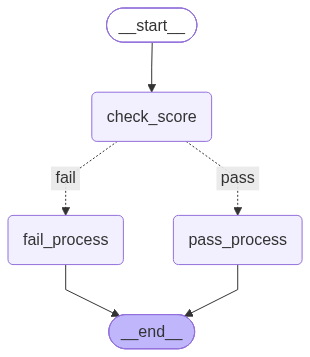

In [8]:
graph

## 그래프 시각화

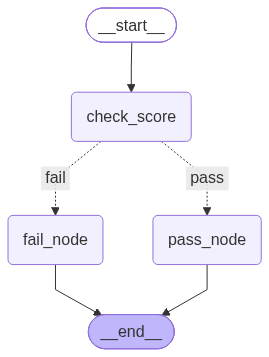

In [2]:
from IPython.display import Image, display

# PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())

In [10]:
score = 20  # 예시 점수
result = graph.invoke({"score": score})

check_score_node: 현재 점수는 20점입니다.
불합격


In [12]:
# 테스트 데이터
scores = [(80, "합격"), (45, "불합격"), (60, "합격")]

# 테스트 실행
for score, expected in scores:
    print(f"\n입력 점수: {score}")
    result = graph.invoke({"score": score, "result": "미정"})
    print("최종 State:", result)
    #assert result["result"] == expected


입력 점수: 80
check_score_node: 현재 점수는 80점입니다.
합격
최종 State: {'score': 80, 'result': '축하합니다! 합격입니다.'}

입력 점수: 45
check_score_node: 현재 점수는 45점입니다.
불합격
최종 State: {'score': 45, 'result': '죄송합니다. 불합격입니다.'}

입력 점수: 60
check_score_node: 현재 점수는 60점입니다.
합격
최종 State: {'score': 60, 'result': '축하합니다! 합격입니다.'}


`check_score`가 빈 업데이트를 반환해도 Routing 함수는 현재 State의 `score`를 읽는다.  
한 실행에서는 합격 또는 불합격 Node 중 하나만 방문한다.

## 작은 수정 실습
합격 기준을 70점으로 바꾸고 60점의 경로를 다시 관찰한다. 코드를 바꾼 뒤 Graph를 재구성·컴파일한다.

## 이해 확인
1. 기준 60점일 때 60점은 어느 경로인가?  
   **해설:** `>= 60`이므로 합격 경로이다.
2. 이 분기 Graph는 그 자체로 AI Agent인가?  
   **해설:** 아니다. 개발자가 고정한 점수 규칙을 따르는 Workflow이다.

**핵심 정리:** Conditional Edge는 State에 따라 실행 경로를 바꾸지만, 조건의 출처가 개발자 규칙인지 모델 판단인지 구분해야 한다.

## 점검 문제: 가위바위보 승부 판정 Graph
지금까지는 `score` 하나의 값만 보고 분기했다. 이번에는 **두 값을 비교**해서 분기하는 조건부 Edge를 만들어본다. 플레이어와 컴퓨터가 낸 가위바위보를 보고 승/패/무승부를 판정하는 Graph를 직접 구성해본다.

**요구사항**
- State에는 `player`, `computer`, `result` 세 필드가 있다(`player`, `computer`는 `"가위"`, `"바위"`, `"보"` 중 하나).
- Routing 함수는 `player`와 `computer`를 비교해 `"win"`, `"lose"`, `"draw"` 중 하나를 반환한다.
- 가위는 보를 이기고, 바위는 가위를 이기고, 보는 바위를 이긴다.
- 각 결과에 맞는 Node를 만들어 `result`에 `"승리"`, `"패배"`, `"무승부"`를 채운다.

**직접 풀어보기 전에 예측할 것**
- `player`와 `computer`가 같을 때는 어느 경로로 가야 하는가?
- 경우의 수는 3×3 = 9가지이다. 이것을 if문 몇 개로 줄여서 표현할 수 있을까? (힌트: "이기는 조합"만 따로 집합으로 정의한다)

**자가 점검용 테스트** (아래 입력으로 직접 작성한 Graph를 실행해 비교한다)
| player | computer | 기대 result |
|---|---|---|
| 가위 | 보 | 승리 |
| 가위 | 바위 | 패배 |
| 가위 | 가위 | 무승부 |
| 바위 | 가위 | 승리 |
| 보 | 바위 | 승리 |
| 보 | 가위 | 패배 |

`builder3 = StateGraph(RPSState)`부터 시작해 직접 구현해본 뒤, 풀이는 같은 폴더의 `03_문제해결_graph.ipynb`에서 확인한다.